# 14. A positive control: data built so that a deep model should win

**The answer, first** (written after all 24 settings were scored).

- **No deep model beats the best simple detector by the 12-point margin at any of the 24 settings. On data built so that a deep model should win, our deep setup (notebook 09's autoencoder and LSTM, unchanged) did not.** That is a limit of this project's deep setup, and it is in the README.
- **Prediction P1** (at bend 0 the autoencoder matches PCA and the straight-link detector) **held with 10,000 and 50,000 readings, and failed with 2,000**: there the autoencoder catches 0.005 to 0.02 of faulty readings where PCA catches every one. Trained by notebook 09's recipe on 1,600 readings, it does not fit even a flat surface closely enough to see a fault of half a sensor's spread.
- **Prediction P2** (at bend 1 or more, 40 sensors, 2,000 or 10,000 readings, the autoencoder beats nearest-neighbour and kernel PCA by 12 points) **failed at all four settings**: all three catch almost nothing (0.00 to 0.05), so they tie.
- **The autoencoder learns the bent shape only with 50,000 readings**: with 10 sensors at bend 0.5 it catches 0.43 (PCA 0.00), and with 40 sensors 0.85 to 1.00 at every bend above 0 (PCA, nearest neighbour and kernel PCA 0.00). But there a link detector matches it: the curved-link detector (0.48) with 10 sensors, the straight-link detector (1.00) with 40.
- **Found after seeing results: the generator has two weaknesses** (section 5). With 40 sensors the bent surface is not bent for the straight-link detector: every sensor is built from the same 12 functions of the three drivers, so any one sensor is an exact straight-line mix of the other 39, and the straight-link detector catches every faulty reading at every bend. With 10 sensors, where the surface really is bent for every detector, the normal readings far out on the shape's arms are modelled badly by everyone, and those rare large errors set each alarm line above a fault of half a spread. A positive control that works would need bends no straight line through the other sensors can follow, and faults large against the models' worst normal errors.

Every notebook so far asked whether a deep model beats simple detectors on real or realistic plant data, and none did once the simple side was complete (notebooks 09, 10 and 13). That leaves a question: **could our deep setup win anywhere?** If it cannot win even on data built for it, the earlier "no" says as much about the setup as about the plants.

This notebook builds such data. Everything in section 1 was written down before any detector was run on it (`adlab/posctl.py`).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import explore, posctl

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)

## 1. The design (fixed before any results)

**Normal behaviour.** Three hidden drivers move smoothly and never repeat exactly: each is random noise smoothed over about 20 readings. Every sensor is a mix of the drivers:

- a **straight part** (a weighted sum of the three drivers),
- a **bent part**, made of squares of the drivers, products of pairs of drivers, and sines of the drivers, with weights drawn at random from one fixed seed, scaled to the same size as the straight part, and multiplied by the **bend strength** dial,
- **noise** of 2 to 5% of the sensor's spread.

So at bend 0 every sensor lies on a flat surface (three straight directions); as the bend grows, the surface curls. The sensors never visit the same state twice, so a lookup of past readings cannot simply find the present one.

**The fault: a broken bent link.** In each faulty run of 300 readings, from reading 150 on, one sensor (drawn at random) is moved by half its normal spread, towards the middle of its range, and held there. It stays inside its normal range and keeps its normal level and spread; only its link to the other sensors breaks. A detector has to know where that sensor *should* be, given the others, to see it.

**Three dials, 24 settings.** Bend strength 0, 0.5, 1 and 2; 10 or 40 sensors; 2,000, 10,000 or 50,000 normal readings to fit on. Each setting is scored on 40 faulty runs, with one alarm line from 20 separate normal runs (1 false alarm in 100). Ranges come from resampling runs.

**Detectors.** The full lineup: the eight standard detectors, the kinked-link detector, the straight forecaster, PCA scored like the autoencoder, and the classic detectors added this round (nearest normal reading on all sensors with k = 1 and 5, dynamic PCA, CVA, kernel PCA). The **autoencoder** and the **LSTM** use notebook 09's design unchanged: the autoencoder's bottleneck is as wide as the number of components PCA keeps, and the LSTM's window and size are chosen on held-aside normal data. Three seeds. Nothing is tuned on faults.

**Two predictions, fixed in advance.**

- **P1.** At bend 0, PCA and the straight-link detector match the autoencoder (no gap of 12 points either way).
- **P2.** At bend 1 or more, with 40 sensors and limited data (2,000 or 10,000 readings), the autoencoder beats both nearest-neighbour checks and kernel PCA by the 12-point margin.

**What is reported.** The first setting (going up the bend, then the sensors, then the readings) where any deep model beats the best simple detector by 12 points with a range clear of zero. If there is none, that is said plainly, as a limit of this project's deep setup.

## 2. What the normal data look like

Two pairs of sensors at each bend strength, and how many components PCA keeps: that number is the autoencoder's bottleneck.

components PCA keeps (90%)  \
bend     sensors                                  
bend 0   10 sensors                           3   
         40 sensors                           3   
bend 0.5 10 sensors                           4   
         40 sensors                           5   
bend 1   10 sensors                           5   
         40 sensors                           7   
bend 2   10 sensors                           6   
         40 sensors                           8   

                     variance in the first 3 components  
bend     sensors                                         
bend 0   10 sensors                               0.999  
         40 sensors                               0.999  
bend 0.5 10 sensors                               0.888  
         40 sensors                               0.833  
bend 1   10 sensors                               0.726  
         40 sensors                               0.617  
bend 2   10 sensors                               0.719  
         40 sensors                               0.594

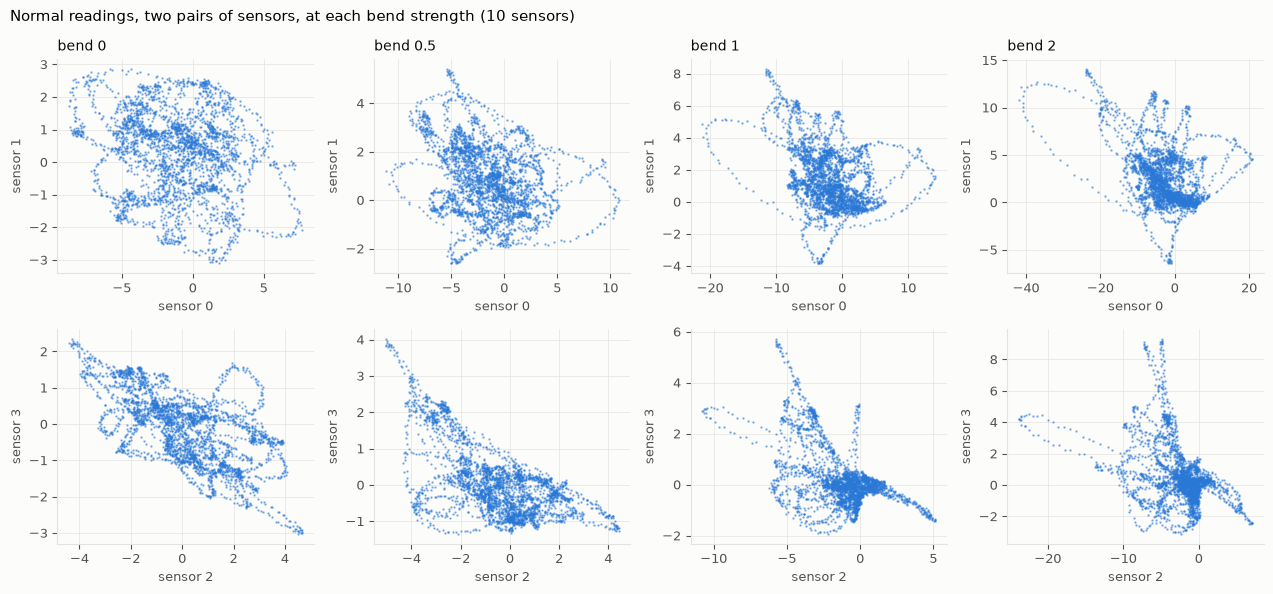

In [2]:
posctl.look();
posctl.components_table()

**What this shows.** At bend 0 the readings fill a flat shape: three components hold 99.9% of the variance, exactly the three drivers. As the bend grows the shape curls and grows arms (the squares and products of the drivers), and a straight model needs more directions to cover it: at bend 1, PCA keeps 5 components (10 sensors) or 7 (40 sensors) to reach 90% of the variance, and at bend 2, 6 or 8. Those are the autoencoder's bottleneck widths, by notebook 09's rule, although the shape itself is only three-dimensional. Sensors still never repeat a state: the drivers wander continuously.

## 3. One fault, drawn

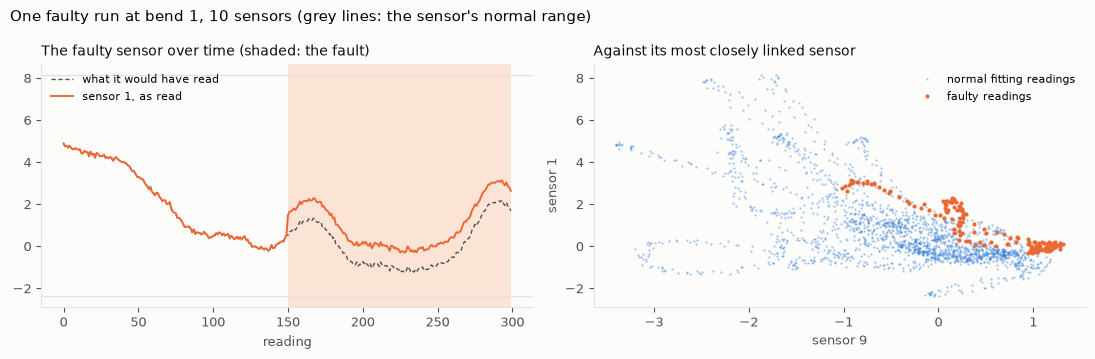

In [3]:
posctl.fault_picture(bend=1.0, d=10, run=0);

**What this shows.** The faulty sensor (orange) is pushed half its normal spread away from where it would have read (dashed), and stays inside its normal range (grey lines). On its own it looks ordinary. Against its most closely linked sensor (right), many faulty readings still sit inside the normal cloud: a pair of sensors is not enough. A detector has to place the sensor using all the others at once.

## 4. Scoring

Every detector on every setting, cached in `results/cache` (about five hours the first time on this laptop).

*Two decisions made during the run, for compute only, before any result at 10,000 or 50,000 readings was seen and without faulty data:* (1) at 10,000 and 50,000 readings the LSTM does not choose its setting again; it uses the setting it chose on held-aside normal data at 2,000 readings for the same bend and sensors (window 10; 64 units in 2 layers for 10 sensors at bend 0, otherwise 32 units in 1 layer), as the generated campaign reused IndPenSim's choice; (2) with over 20,000 fitting readings, the matrix profile's overall scale comes from the last 2,000 fitting readings joined against the rest instead of a self-join of all of them. Every score, the faulty runs' and the line runs' alike, is divided by that one number, so no catch rate changes.

In [4]:
for s in posctl.settings():
    posctl.score(*s, verbose=False)        # several hours the first time; then read from results/cache

## 5. Every setting: the deep models against the best simple detector

autoencoder  LSTM    best simple detector  \
bend sensors fitting readings                                             
0    10      2000                   0.005 0.005          PCA (T2 + SPE)   
             10000                   0.97 0.856          PCA (T2 + SPE)   
             50000                      1     1          PCA (T2 + SPE)   
     40      2000                   0.017 0.001          PCA (T2 + SPE)   
             10000                      1  0.53          PCA (T2 + SPE)   
             50000                      1     1          PCA (T2 + SPE)   
0.5  10      2000                   0.008 0.006             CUSUM chart   
             10000                  0.071 0.004    Kinked-link residual   
             50000                  0.427 0.318    Curved-link residual   
     40      2000                   0.003 0.004  Straight-link residual   
             10000                  0.223 0.002  Straight-link residual   
             50000                  0.998 0.836  Straight-link residual   
1    10      2000                   0.002 0.001             CUSUM chart   
             10000                  0.006 0.002     Straight forecaster   
             50000                  0.164 0.011             CUSUM chart   
     40      2000                       0 0.001  Straight-link residual   
             10000                  0.047 0.002  Straight-link residual   
             50000                  0.851 0.396  Straight-link residual   
2    10      2000                   0.003 0.001             CUSUM chart   
             10000                  0.001 0.003     Straight forecaster   
             50000                  0.003 0.008             CUSUM chart   
     40      2000                   0.002 0.002  Straight-link residual   
             10000                  0.023 0.001  Straight-link residual   
             50000                  0.857 0.316  Straight-link residual   

                              best simple caught  \
bend sensors fitting readings                      
0    10      2000                              1   
             10000                             1   
             50000                             1   
     40      2000                              1   
             10000                             1   
             50000                             1   
0.5  10      2000                          0.039   
             10000                         0.305   
             50000                         0.476   
     40      2000                              1   
             10000                             1   
             50000                             1   
1    10      2000                          0.059   
             10000                         0.059   
             50000                         0.095   
     40      2000                              1   
             10000                             1   
             50000                             1   
2    10      2000                          0.066   
             10000                         0.065   
             50000                          0.07   
     40      2000                              1   
             10000                             1   
             50000                             1   

                              best deep minus best simple, points  \
bend sensors fitting readings                                       
0    10      2000                                         -99.511   
             10000                                         -2.972   
             50000                                              0   
     40      2000                                         -98.306   
             10000                                         -0.039   
             50000                                              0   
0.5  10      2000                                          -3.106   
             10000                                        -23.461   
             50000                  

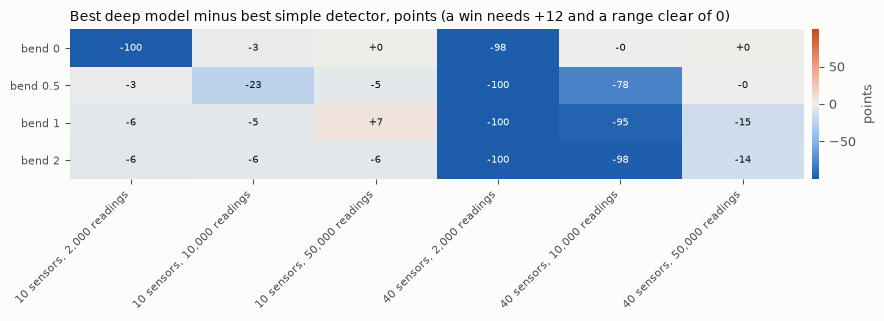

In [5]:
table = posctl.grid()
display(table)
posctl.gap_picture(table);

**What this shows.** Three regimes, none of them a deep win:

- **Bend 0 (a flat surface).** PCA and the straight-link detector catch every faulty reading at every size. The autoencoder catches almost nothing with 2,000 readings (0.005 and 0.02), 0.97 and 1.00 with 10,000, and every reading with 50,000. The LSTM follows it (0.86 and 0.53 at 10,000, 1.00 at 50,000). So with too little data, notebook 09's training recipe (at most 100 passes; every one of these trainings used all 100) leaves the network too rough to see a fault that a straight line sees at once.
- **40 sensors, bend 0.5 to 2.** The straight-link and curved-link detectors catch every faulty reading at every bend and size (*found after seeing results:* each sensor is a mix of the same 12 functions of three drivers: three straight, three squares, three products, three sines; with 40 sensors any one is a straight-line mix of the other 39, so the bend is invisible to a straight-link model). PCA, which keeps only 5 to 9 directions by its 90% rule, catches nothing. The autoencoder catches 0.00 to 0.22 with 2,000 or 10,000 readings, and **0.85 to 1.00 with 50,000**: then it beats PCA, nearest neighbour and kernel PCA by about 85 points, but ties the straight-link detector (0 to −15 points).
- **10 sensors, bend 0.5 to 2 (a truly bent surface).** Nearly everything misses: the best simple detector catches 0.04 to 0.48, mostly the CUSUM chart at 0.04 to 0.09. The largest catch is at bend 0.5 with 50,000 readings, where the curved-link detector catches 0.48 and the autoencoder 0.43 (a tie; PCA 0.00). At bend 1 with 50,000 readings the autoencoder catches 0.16 against the CUSUM chart's 0.09: +7 points (range −10 to +62), its best showing, and still a tie. At bend 2 nothing catches more than 0.07. The normal readings on the shape's sparse arms are modelled badly by every detector, and their rare large errors set every alarm line above a shift of half a spread.

Nearest neighbour and kernel PCA catch almost nothing anywhere: the drivers never repeat, so a new normal reading is never close to a stored one, and a fault does not move a reading much further away than normal readings already are.

## 6. The two predictions

In [6]:
posctl.predictions()

gaps (autoencoder minus each)  \
prediction                                                                                              bend sensors fitting readings                                                                                                                                                                                              
P1: at bend 0, PCA and straight-link match the autoencoder                                              0    10      2000                                                                                                 PCA (T2 + SPE): -99.5 (-100.4 to -61.9) behind; Straight-link residual: -99.5 (-100.4 to -61.9) behind   
                                                                                                                     10000                                                                                                              PCA (T2 + SPE): -3.0 (-9.8 to +3.7) tie; Straight-link residual: -3.0 (-9.8 to +3.7) tie   
                                                                                                                     50000                                                                                                              PCA (T2 + SPE): +0.0 (+0.0 to +0.0) tie; Straight-link residual: +0.0 (+0.0 to +0.0) tie   
                                                                                                             40      2000                                                                                                 PCA (T2 + SPE): -98.3 (-100.7 to -75.3) behind; Straight-link residual: -98.3 (-100.7 to -75.3) behind   
                                                                                                                     10000                                                                                                              PCA (T2 + SPE): -0.0 (-0.2 to -0.0) tie; Straight-link residual: -0.0 (-0.2 to -0.0) tie   
                                                                                                                     50000                                                                                                              PCA (T2 + SPE): +0.0 (+0.0 to +0.0) tie; Straight-link residual: +0.0 (+0.0 to +0.0) tie   
P2: at bend 1 or more, 40 sensors, limited data, the autoencoder beats nearest-neighbour and kernel PCA 1    40      2000                 Nearest normal reading, all sensors (k = 1): -0.0 (-0.8 to +0.1) tie; Nearest normal readings, all sensors (k = 5): -0.0 (-0.8 to +0.1) tie; Kernel PCA (RBF): -0.1 (-0.7 to +0.1) tie   
                                                                                                                     10000             Nearest normal reading, all sensors (k = 1): +4.5 (+2.5 to +20.8) tie; Nearest normal readings, all sensors (k = 5): +4.5 (+2.5 to +20.8) tie; Kernel PCA (RBF): +4.5 (+2.4 to +20.9) tie   
                                                                                                        2    40      2000                 Nearest normal reading, all sensors (k = 1): +0.1 (-0.7 to +0.2) tie; Nearest normal readings, all sensors (k = 5): +0.1 (-0.7 to +0.2) tie; Kernel PCA (RBF): +0.1 (-0.4 to +0.2) tie   
                                                                                                                     10000             Nearest normal reading, all sensors (k = 1): +2.1 (-2.6 to +18.6) tie; Nearest normal readings, all sensors (k = 5): +2.1 (-2.6 to +18.6) tie; Kernel PCA (RBF): +2.1 (-2.6 to +18.6) tie   

                                                                                                                                        held  
prediction                                                                                              bend sensors fitting readings         
P1: at bend 0, PCA and straight-link match the autoencoder                                              0    10     

**What this shows.** **P1 held in four of six settings** (10,000 and 50,000 readings: ties within 3 points) **and failed in two** (2,000 readings: the autoencoder is 98 to 100 points behind PCA and the straight-link detector). **P2 failed in all four settings**: with 40 sensors and 2,000 or 10,000 readings, the autoencoder, the nearest-neighbour checks and kernel PCA all catch 0.00 to 0.05, so every gap is a tie near zero (at most +4.5 points). The autoencoder's advantage over them appears only with 50,000 readings, which P2 did not cover, and there the straight-link detector catches everything.

## 7. The first setting where a deep model wins

In [7]:
posctl.first_win()

**What this shows. There is none.** At no setting does any deep model beat the best simple detector by 12 points with a range clear of zero. The nearest is the autoencoder at bend 1, 10 sensors and 50,000 readings (+7 points, range −10 to +62, a tie).

**Read it as a limit of this project's deep setup, together with this generator.** The deep models use notebook 09's design unchanged: a bottleneck as wide as PCA's component count, at most 100 training passes, and settings chosen on held-aside normal data. On a flat surface they need 10,000 readings to match PCA. On a truly bent one they need 50,000 to learn the shape, and then a link detector matches them. A test that a deep model could win would need a bend that no straight line through the other sensors can follow (more independent bent functions than sensors), faults that stand out against the models' worst normal errors, and perhaps a training budget that grows with the data. None of these was tried here: they would be choices made after seeing these results.

## 8. Every detector, setting by setting (for reference)

In [8]:
for s in posctl.settings():
    print(f"bend {s[0]:g}, {s[1]} sensors, {s[2]:,} fitting readings")
    display(posctl.all_detectors(*s).T)

bend 0, 10 sensors, 2,000 fitting readings


detector,Kinked-link residual,PCA (T2 + SPE),Straight forecaster,CVA (T2 + Q),Curved-link residual,Straight-link residual,Dynamic PCA (2 lags),"PCA, scored like the autoencoder",CUSUM chart,Isolation Forest,Autoencoder,LSTM forecaster,Kernel PCA (RBF),"Nearest normal reading, all sensors (k = 1)","Nearest normal readings, all sensors (k = 5)",Rolling z-score,EWMA chart,Matrix Profile
catch rate,1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),0.03 (0.00-0.07),0.01 (0.00-0.04),0.00 (0.00-0.38),0.00 (0.00-0.05),0.00 (0.00-0.02),0.00 (0.00-0.02),0.00 (0.00-0.02),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01)


bend 0, 10 sensors, 10,000 fitting readings


detector,Kinked-link residual,PCA (T2 + SPE),Straight forecaster,CVA (T2 + Q),Curved-link residual,Straight-link residual,Dynamic PCA (2 lags),"PCA, scored like the autoencoder",Autoencoder,LSTM forecaster,CUSUM chart,Isolation Forest,"Nearest normal readings, all sensors (k = 5)","Nearest normal reading, all sensors (k = 1)",EWMA chart,Rolling z-score,Matrix Profile,Kernel PCA (RBF)
catch rate,1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),0.97 (0.87-1.00),0.86 (0.66-1.00),0.03 (0.01-0.07),0.01 (0.00-0.03),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.02),0.00 (0.00-0.01)


bend 0, 10 sensors, 50,000 fitting readings


detector,Kinked-link residual,PCA (T2 + SPE),LSTM forecaster,CVA (T2 + Q),Curved-link residual,Straight-link residual,Straight forecaster,Autoencoder,Dynamic PCA (2 lags),"PCA, scored like the autoencoder",CUSUM chart,Isolation Forest,"Nearest normal readings, all sensors (k = 5)","Nearest normal reading, all sensors (k = 1)",Matrix Profile,Rolling z-score,EWMA chart,Kernel PCA (RBF)
catch rate,1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),0.06 (0.02-0.11),0.01 (0.00-0.03),0.00 (0.00-0.02),0.00 (0.00-0.02),0.00 (0.00-0.09),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.02)


... (38 outputs left out)

bend 2, 40 sensors, 10,000 fitting readings


detector,Kinked-link residual,Straight forecaster,Curved-link residual,Straight-link residual,CVA (T2 + Q),CUSUM chart,Autoencoder,"PCA, scored like the autoencoder",PCA (T2 + SPE),Dynamic PCA (2 lags),Kernel PCA (RBF),"Nearest normal reading, all sensors (k = 1)","Nearest normal readings, all sensors (k = 5)",LSTM forecaster,Isolation Forest,Rolling z-score,EWMA chart,Matrix Profile
catch rate,1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),0.99 (0.84-1.00),0.03 (0.00-0.08),0.02 (0.00-0.22),0.00 (0.00-0.02),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.00)


bend 2, 40 sensors, 50,000 fitting readings


detector,Kinked-link residual,Straight forecaster,Curved-link residual,Straight-link residual,CVA (T2 + Q),Autoencoder,LSTM forecaster,"PCA, scored like the autoencoder",CUSUM chart,"Nearest normal reading, all sensors (k = 1)",Kernel PCA (RBF),"Nearest normal readings, all sensors (k = 5)",PCA (T2 + SPE),Matrix Profile,Dynamic PCA (2 lags),Isolation Forest,Rolling z-score,EWMA chart
catch rate,1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (1.00-1.00),1.00 (0.99-1.00),0.86 (0.52-1.00),0.32 (0.00-1.00),0.13 (0.06-0.28),0.03 (0.00-0.09),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.01),0.00 (0.00-0.03),0.00 (0.00-0.01),0.00 (0.00-0.00),0.00 (0.00-0.01),0.00 (0.00-0.01)
